# 01 · What drives a Smiski's resale premium?

**Question.** For a given figure, how far above retail does it sell on the resale market, and which attributes explain that?

**Target:** `premium_pct` = (median sold price ÷ retail price − 1) × 100, per figure per quarterly snapshot.
**Features:** series theme, rarity tier, retail price, release season, months since launch, collab flag, search interest at launch.

**Plan**
1. Build the feature table and say plainly how little independent data there is.
2. Validate *by whole series* (leave-one-series-out) and by time, never with a random split.
3. Compare against two baselines: the training mean, and "mean premium per rarity tier".
4. Linear regression → LightGBM / XGBoost.
5. SHAP for the drivers, with stability across refits.
6. Prediction intervals, checked on a time hold-out.
7. Export JSON for the website.

In [1]:
import sys, pathlib, warnings, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut, KFold
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import lightgbm as lgb, xgboost as xgb, shap

from smiskis.data import load, banner, provenance
from smiskis.paths import SITE_DATA, ROOT as PROJECT
from smiskis import viz
viz.set_style()
FIG = PROJECT / "reports"; FIG.mkdir(exist_ok=True)
RNG = 7
print(banner("series", "figures", "resale", "trends"))

DATA PROVENANCE  [series: scraped | figures: scraped | resale: simulated | trends: scraped]
  !! resale is SIMULATED (see src/smiskis/seed.py). Results below describe the simulation, not the real Smiski market. Run `make scrape` with network access to replace it.


## 1 · Feature table

In [2]:
resale, figs, series = load("resale"), load("figures"), load("series")
df = (resale.merge(figs.drop(columns=["retail_usd", "collab"]), on="figure_id")
            .merge(series[["series_id", "retail_usd", "collab", "launch_interest"]], on="series_id"))

SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
df["release_season"] = df["release_date"].dt.month.map(SEASON)
df["rarity_ord"] = df["rarity_tier"].map({"common": 0, "uncommon": 1, "secret": 2})
df = df.sort_values(["release_date", "figure_id", "snapshot_date"]).reset_index(drop=True)

NUM = ["rarity_ord", "retail_usd", "months_since_launch", "collab", "launch_interest"]
CAT = ["theme", "release_season"]
CAT_LEVELS = {c: sorted(df[c].unique()) for c in CAT}

def design(frame):
    """One-hot with fixed levels so every fold has identical columns."""
    X = frame[NUM].astype(float).copy()
    for c in CAT:
        for lv in CAT_LEVELS[c]:
            X[f"{c}={lv}"] = (frame[c] == lv).astype(float)
    return X

X, y, groups = design(df), df["premium_pct"].values, df["series_id"].values
parent = {col: col.split("=")[0] for col in X.columns}          # dummy -> original feature
print(f"rows={len(df)}  figures={df.figure_id.nunique()}  series={df.series_id.nunique()}  features={X.shape[1]}")
print("-> effective independent sample is about the number of SERIES, not rows. Small data: expect high variance.")
df[["figure_id", "series_id", "theme", "rarity_tier", "retail_usd", "release_season", "months_since_launch",
    "collab", "launch_interest", "premium_pct"]].head()

rows=483  figures=126  series=18  features=24
-> effective independent sample is about the number of SERIES, not rows. Small data: expect high variance.


,figure_id,series_id,theme,rarity_tier,retail_usd,release_season,months_since_launch,collab,launch_interest,premium_pct
0,S01-01,S01,Original,common,12.99,spring,118.00,0,0.4,26.88
1,S01-01,S01,Original,common,12.99,spring,120.96,0,0.4,27.33
2,S01-01,S01,Original,common,12.99,spring,123.95,0,0.4,20.16
3,S01-01,S01,Original,common,12.99,spring,126.97,0,0.4,29.95
4,S01-02,S01,Original,common,12.99,spring,118.00,0,0.4,15.54


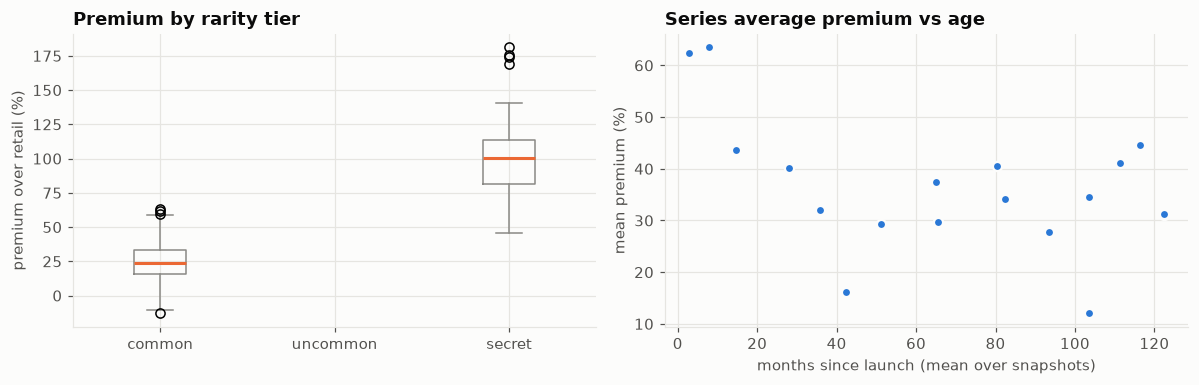

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = ["common", "uncommon", "secret"]
axes[0].boxplot([df.loc[df.rarity_tier == t, "premium_pct"] for t in order], tick_labels=order,
                medianprops=dict(color=viz.SERIES[1], lw=2), boxprops=dict(color=viz.NEUTRAL), whiskerprops=dict(color=viz.NEUTRAL), capprops=dict(color=viz.NEUTRAL))
axes[0].set_title("Premium by rarity tier"); axes[0].set_ylabel("premium over retail (%)")
s = df.groupby("series_id").agg(m=("months_since_launch", "mean"), p=("premium_pct", "mean"))
axes[1].scatter(s.m, s.p, s=36, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=1.5)
axes[1].set_title("Series average premium vs age"); axes[1].set_xlabel("months since launch (mean over snapshots)"); axes[1].set_ylabel("mean premium (%)")
plt.tight_layout(); plt.savefig(FIG / "premium_eda.png", dpi=150); plt.show()

## 2 · Models and validation

Figures in the same series look alike (same theme, same launch, same hype), so a random split lets the model "recognise" the series and **inflates** scores. We hold out **entire series** (leave-one-series-out, LOSO), and separately test on **later series** the model has never seen.

Two baselines keep the comparison honest: the training mean, and the mean premium for each rarity tier (what an experienced collector would guess).

In [4]:
class RarityMean:
    """Baseline: predict the training-set mean premium of the figure's rarity tier."""
    def fit(self, X, y):
        self.m_ = {r: y[X["rarity_ord"].values == r].mean() for r in np.unique(X["rarity_ord"])}
        self.g_ = y.mean(); return self
    def predict(self, X):
        return np.array([self.m_.get(r, self.g_) for r in X["rarity_ord"].values])

class MeanBaseline:
    def fit(self, X, y): self.m_ = y.mean(); return self
    def predict(self, X): return np.full(len(X), self.m_)

def make_models():
    return {
        "Baseline: mean":        MeanBaseline(),
        "Baseline: rarity mean": RarityMean(),
        "Linear (ridge)":        make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
        "LightGBM":              lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=6, min_child_samples=12,
                                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                                                   random_state=RNG, verbose=-1, n_jobs=2),
        "XGBoost":               xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=5,
                                                  subsample=0.8, colsample_bytree=0.8, reg_lambda=5, random_state=RNG, n_jobs=2),
    }

def metrics(y_true, y_pred):
    return dict(MAE=mean_absolute_error(y_true, y_pred), RMSE=mean_squared_error(y_true, y_pred) ** 0.5, R2=r2_score(y_true, y_pred))

def oof_predict(cv_splits):
    out = {k: np.full(len(df), np.nan) for k in make_models()}
    for tr, te in cv_splits:
        for name, mdl in make_models().items():
            mdl.fit(X.iloc[tr], y[tr]); out[name][te] = mdl.predict(X.iloc[te])
    return out

loso = list(LeaveOneGroupOut().split(X, y, groups))
oof = oof_predict(loso)
res = pd.DataFrame({k: metrics(y, v) for k, v in oof.items()}).T
res["MAE vs mean baseline"] = 1 - res["MAE"] / res.loc["Baseline: mean", "MAE"]
res["MAE vs rarity baseline"] = 1 - res["MAE"] / res.loc["Baseline: rarity mean", "MAE"]
res.round(3)

,MAE,RMSE,R2,MAE vs mean baseline,MAE vs rarity baseline
Baseline: mean,21.760,31.692,-0.016,0.000,-0.750
Baseline: rarity mean,12.431,16.869,0.712,0.429,0.000
Linear (ridge),11.730,15.887,0.745,0.461,0.056
LightGBM,11.996,15.983,0.742,0.449,0.035
XGBoost,11.981,15.656,0.752,0.449,0.036


### How sure are we that the model beats the baseline?
Resampling **series** (not rows) with replacement, because series are the independent units.

In [5]:
def series_bootstrap(model, base="Baseline: rarity mean", n=2000):
    rng = np.random.default_rng(RNG)
    sids = np.unique(groups)
    err_m = pd.Series(np.abs(y - oof[model])).groupby(groups).mean()
    err_b = pd.Series(np.abs(y - oof[base])).groupby(groups).mean()
    diffs = []
    for _ in range(n):
        pick = rng.choice(sids, len(sids), replace=True)
        diffs.append(1 - err_m[pick].mean() / err_b[pick].mean())
    return np.percentile(diffs, [5, 50, 95])

boot = {m: series_bootstrap(m) for m in ["Linear (ridge)", "LightGBM", "XGBoost"]}
boot_df = pd.DataFrame(boot, index=["5%", "median", "95%"]).T.mul(100).round(1)
boot_df.columns = ["improvement 5%", "median", "improvement 95%"]
print("MAE reduction vs the rarity-mean baseline (%), 90% bootstrap interval over series")
boot_df

MAE reduction vs the rarity-mean baseline (%), 90% bootstrap interval over series


,improvement 5%,median,improvement 95%
Linear (ridge),-0.5,7.5,14.7
LightGBM,-3.6,7.5,18.3
XGBoost,-5.7,7.8,20.7


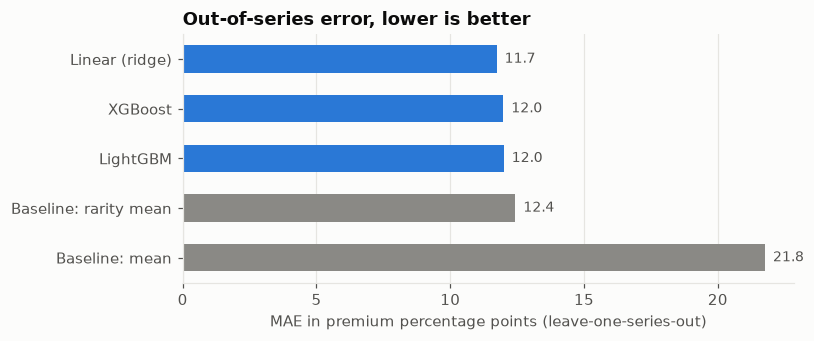

In [6]:
rows = []
for name, v in oof.items():
    rows.append((name, res.loc[name, "MAE"]))
order_ = sorted(rows, key=lambda r: r[1])
fig, ax = plt.subplots(figsize=(7.5, 3.2))
cols = [viz.NEUTRAL if n.startswith("Baseline") else viz.SERIES[0] for n, _ in order_]
ax.barh([n for n, _ in order_][::-1], [v for _, v in order_][::-1], color=cols[::-1], height=0.55)
for i, (n, v) in enumerate(order_[::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=9, color=viz.INK2)
ax.set_xlabel("MAE in premium percentage points (leave-one-series-out)"); ax.set_title("Out-of-series error, lower is better")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.savefig(FIG / "premium_models.png", dpi=150); plt.show()

### Sanity check: random split vs whole-series hold-out
If the random split looks much better, that gap is leakage, not skill.

In [7]:
rand_splits = list(KFold(n_splits=5, shuffle=True, random_state=RNG).split(X))
oof_rand = {k: np.full(len(df), np.nan) for k in ["LightGBM"]}
for tr, te in rand_splits:
    m = make_models()["LightGBM"].fit(X.iloc[tr], y[tr]); oof_rand["LightGBM"][te] = m.predict(X.iloc[te])
leak = pd.DataFrame({"random 5-fold": metrics(y, oof_rand["LightGBM"]), "leave-one-series-out": metrics(y, oof["LightGBM"])}).T
print("LightGBM"); leak.round(3)

LightGBM


,MAE,RMSE,R2
random 5-fold,8.687,11.311,0.871
leave-one-series-out,11.996,15.983,0.742


### Time hold-out: train on older series, test on the newest ones

In [8]:
CUT = pd.Timestamp("2025-01-01")
is_train = (df["release_date"] < CUT).values
tr_idx, te_idx = np.where(is_train)[0], np.where(~is_train)[0]
print(f"train: {df.loc[is_train,'series_id'].nunique()} series, {len(tr_idx)} rows | test: {df.loc[~is_train,'series_id'].nunique()} newest series, {len(te_idx)} rows")
hold = {}
for name, mdl in make_models().items():
    mdl.fit(X.iloc[tr_idx], y[tr_idx]); hold[name] = mdl.predict(X.iloc[te_idx])
hold_res = pd.DataFrame({k: metrics(y[te_idx], v) for k, v in hold.items()}).T
hold_res["MAE vs rarity baseline"] = 1 - hold_res["MAE"] / hold_res.loc["Baseline: rarity mean", "MAE"]
hold_res.round(3)

train: 15 series, 420 rows | test: 3 newest series, 63 rows


,MAE,RMSE,R2,MAE vs rarity baseline
Baseline: mean,27.739,48.311,-0.274,-0.166
Baseline: rarity mean,23.796,30.777,0.483,0.000
Linear (ridge),15.496,21.868,0.739,0.349
LightGBM,20.195,28.797,0.547,0.151
XGBoost,19.784,28.010,0.572,0.169


## 3 · What drives the premium? (SHAP)

SHAP values are additive, so one-hot columns are summed back to their original feature (`theme`, `release_season`). The model is refit leaving each series out in turn; the spread of those importances shows how stable the ranking is.

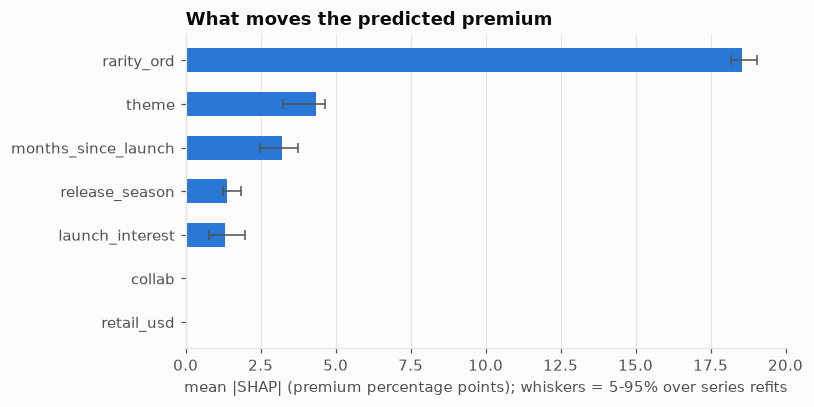

,mean|SHAP|,5%,95%,direction
rarity_ord,18.55,18.18,19.06,higher value -> higher premium
theme,4.35,3.25,4.64,category-dependent
months_since_launch,3.21,2.46,3.73,higher value -> lower premium
release_season,1.38,1.25,1.84,category-dependent
launch_interest,1.33,0.76,1.98,higher value -> higher premium
collab,0.00,0.00,0.00,mixed / non-monotonic
retail_usd,0.00,0.00,0.00,mixed / non-monotonic


In [9]:
final = make_models()["LightGBM"].fit(X, y)
sv = shap.TreeExplainer(final).shap_values(X)
sv_df = pd.DataFrame(sv, columns=X.columns)
grouped = sv_df.T.groupby(parent).sum().T                       # per-row SHAP by original feature
imp = grouped.abs().mean().sort_values(ascending=False)

# stability: mean |SHAP| for every leave-one-series-out refit
stab = []
for tr, _ in loso:
    m = make_models()["LightGBM"].fit(X.iloc[tr], y[tr])
    s_ = pd.DataFrame(shap.TreeExplainer(m).shap_values(X), columns=X.columns).T.groupby(parent).sum().T
    stab.append(s_.abs().mean())
stab = pd.DataFrame(stab)[imp.index]
lo, hi = stab.quantile(0.05), stab.quantile(0.95)
lo, hi = np.minimum(lo, imp), np.maximum(hi, imp)          # whiskers always bracket the full-data value

# direction for numeric features: sign of correlation between value and SHAP
direction = {}
for f in NUM:
    c = np.corrcoef(X[f], grouped[f])[0, 1]
    direction[f] = "higher value -> higher premium" if c > 0.1 else "higher value -> lower premium" if c < -0.1 else "mixed / non-monotonic"
for f in CAT: direction[f] = "category-dependent"

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ypos = np.arange(len(imp))[::-1]
ax.barh(ypos, imp.values, color=viz.SERIES[0], height=0.55)
ax.errorbar(imp.values, ypos, xerr=[imp.values - lo[imp.index].values, hi[imp.index].values - imp.values], fmt="none", ecolor=viz.INK2, capsize=3, lw=1)
ax.set_yticks(ypos); ax.set_yticklabels(imp.index)
ax.set_xlabel("mean |SHAP| (premium percentage points); whiskers = 5-95% over series refits")
ax.set_title("What moves the predicted premium"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "premium_shap.png", dpi=150); plt.show()
pd.DataFrame({"mean|SHAP|": imp.round(2), "5%": lo[imp.index].round(2), "95%": hi[imp.index].round(2), "direction": pd.Series(direction)[imp.index]})

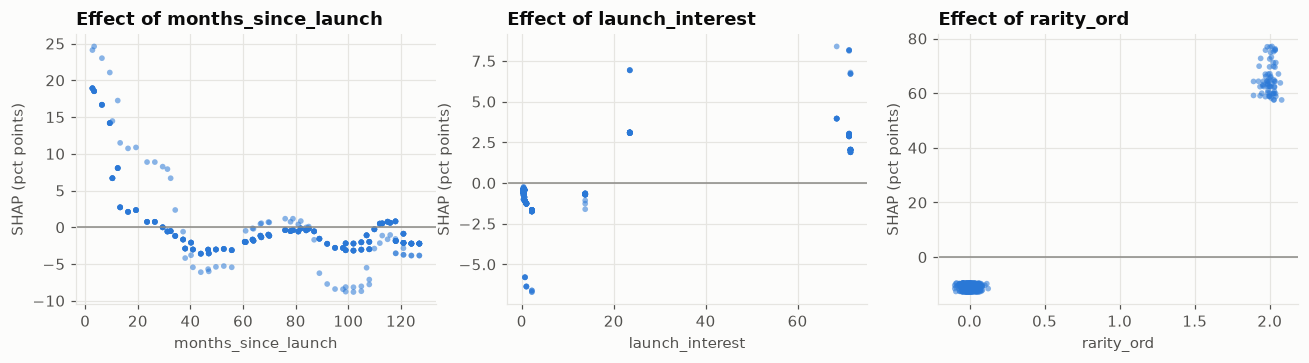

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, f in zip(axes, ["months_since_launch", "launch_interest", "rarity_ord"]):
    jitter = np.random.default_rng(1).normal(0, 0.04, len(df)) if f == "rarity_ord" else 0
    ax.scatter(X[f] + jitter, grouped[f], s=14, color=viz.SERIES[0], alpha=0.55, edgecolor="none")
    ax.axhline(0, color=viz.NEUTRAL, lw=1); ax.set_xlabel(f); ax.set_ylabel("SHAP (pct points)"); ax.set_title(f"Effect of {f}")
plt.tight_layout(); plt.savefig(FIG / "premium_shap_dependence.png", dpi=150); plt.show()

## 4 · Uncertainty: prediction intervals

Residuals from the leave-one-series-out predictions are used as an empirical error distribution, **per rarity tier** (secret figures are much harder to price). The interval is then *tested on the time hold-out*, which uses only calibration residuals from older series.

In [11]:
def tier_quantiles(idx, pred):
    r = y[idx] - pred
    out = {}
    for t in (0, 1, 2):
        rr = r[X["rarity_ord"].values[idx] == t]
        out[t] = (np.quantile(rr, 0.10), np.quantile(rr, 0.90)) if len(rr) >= 10 else (np.quantile(r, 0.10), np.quantile(r, 0.90))
    return out

# calibrate on old series only (LOSO inside the training set), test on newest series
inner = [(np.intersect1d(tr, tr_idx), np.intersect1d(te, tr_idx)) for tr, te in loso if len(np.intersect1d(te, tr_idx))]
pred_inner = np.full(len(df), np.nan)
for tr, te in inner:
    pred_inner[te] = make_models()["LightGBM"].fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
q_old = tier_quantiles(tr_idx, pred_inner[tr_idx])
lo_h = hold["LightGBM"] + np.array([q_old[t][0] for t in X["rarity_ord"].values[te_idx]])
hi_h = hold["LightGBM"] + np.array([q_old[t][1] for t in X["rarity_ord"].values[te_idx]])
cov = float(np.mean((y[te_idx] >= lo_h) & (y[te_idx] <= hi_h)))
print(f"Nominal 80% interval -> empirical coverage on the newest series: {cov:.0%}")

# production intervals use the full leave-one-series-out residuals
q_all = tier_quantiles(np.arange(len(df)), oof["LightGBM"])
{k: (round(float(a), 1), round(float(b), 1)) for k, (a, b) in q_all.items()}

Nominal 80% interval -> empirical coverage on the newest series: 57%


{0: (-20.1, 15.1), 1: (-21.4, 16.2), 2: (-26.9, 28.7)}

## 5 · Export for the website
Each figure's *latest-snapshot* prediction comes from the leave-one-series-out model, i.e. from a model that never saw that figure's series. The blind-box simulator reads this file.

In [12]:
latest = df.sort_values("snapshot_date").groupby("figure_id").tail(1)
pred_rows = []
for i in latest.index:
    r = df.loc[i]; p = float(oof["LightGBM"][i]); t = int(r["rarity_ord"])
    p_lo, p_hi = p + q_all[t][0], p + q_all[t][1]
    p, p_lo, p_hi = [max(v, -30.0) for v in (p, p_lo, p_hi)]
    k = 1 + np.array([p, p_lo, p_hi]) / 100
    pred_rows.append(dict(figure_id=r.figure_id, pred_pct=round(p, 1), lo_pct=round(p_lo, 1), hi_pct=round(p_hi, 1),
                          pred_usd=round(r.retail_usd * k[0], 2), lo_usd=round(r.retail_usd * k[1], 2), hi_usd=round(r.retail_usd * k[2], 2)))

# rule-based takeaway text so it stays truthful when the data changes
share = (imp / imp.sum()).round(3)
groups_ = {"rarity": ["rarity_ord"], "launch timing / age": ["months_since_launch", "release_season"],
           "hype at launch": ["launch_interest"], "theme": ["theme"], "collab": ["collab"], "retail price": ["retail_usd"]}
gshare = {g: float(sum(share.get(f, 0) for f in fs)) for g, fs in groups_.items()}
top = sorted(gshare.items(), key=lambda kv: -kv[1])
best_name = res.loc[["Linear (ridge)", "LightGBM", "XGBoost"], "MAE"].idxmin()
gain = float(res.loc[best_name, "MAE vs rarity baseline"])
lo_b, _, hi_b = boot[best_name]
takeaways = [
    f"Biggest driver: {top[0][0]} (~{top[0][1]:.0%} of explained variation), then {top[1][0]} (~{top[1][1]:.0%}).",
    (f"Best model ({best_name}) cuts out-of-series error by {gain:.0%} vs a rarity-tier baseline "
     f"(90% interval {lo_b:.0%} to {hi_b:.0%}). " + ("The interval includes zero: treat this as no reliable gain over the simple baseline." if lo_b <= 0 else "The interval excludes zero.")),
    f"Leakage check: a random split would report R2={leak.loc['random 5-fold','R2']:.2f} vs {leak.loc['leave-one-series-out','R2']:.2f} for whole-series hold-out.",
    f"Interval check: the nominal 80% interval covered {cov:.0%} of the newest series' observations.",
    f"Small data: {df.series_id.nunique()} series / {df.figure_id.nunique()} figures. Rankings above are indicative, not definitive.",
]
for t in takeaways: print("-", t)

def rec(name):
    return dict(model=name, mae=round(res.loc[name, "MAE"], 2), rmse=round(res.loc[name, "RMSE"], 2), r2=round(res.loc[name, "R2"], 3),
                holdout_mae=round(hold_res.loc[name, "MAE"], 2), holdout_r2=round(hold_res.loc[name, "R2"], 3))

out = dict(
    provenance=provenance()["tables"],
    n_rows=int(len(df)), n_figures=int(df.figure_id.nunique()), n_series=int(df.series_id.nunique()),
    models=[rec(n) for n in res.index],
    improvement_vs_rarity_baseline={m: dict(median=round(float(v[1]), 3), lo=round(float(v[0]), 3), hi=round(float(v[2]), 3)) for m, v in boot.items()},
    best_model=best_name,
    leakage=dict(random_cv_r2=round(leak.loc["random 5-fold", "R2"], 3), group_cv_r2=round(leak.loc["leave-one-series-out", "R2"], 3),
                 random_cv_mae=round(leak.loc["random 5-fold", "MAE"], 2), group_cv_mae=round(leak.loc["leave-one-series-out", "MAE"], 2)),
    interval=dict(nominal=0.8, holdout_coverage=round(cov, 3)),
    holdout=dict(cutoff=str(CUT.date()), n_series=int(df.loc[~is_train, "series_id"].nunique()), n_train_series=int(df.loc[is_train, "series_id"].nunique())),
    shap=[dict(feature=f, mean_abs=round(float(imp[f]), 2), lo=round(float(lo[f]), 2), hi=round(float(hi[f]), 2), direction=direction[f]) for f in imp.index],
    figures=pred_rows,
    takeaways=takeaways,
)
(SITE_DATA / "premium.json").write_text(json.dumps(out, indent=1))
print("wrote", SITE_DATA / "premium.json")

- Biggest driver: rarity (~64% of explained variation), then launch timing / age (~16%).
- Best model (Linear (ridge)) cuts out-of-series error by 6% vs a rarity-tier baseline (90% interval -1% to 15%). The interval includes zero: treat this as no reliable gain over the simple baseline.
- Leakage check: a random split would report R2=0.87 vs 0.74 for whole-series hold-out.
- Interval check: the nominal 80% interval covered 57% of the newest series' observations.
- Small data: 18 series / 126 figures. Rankings above are indicative, not definitive.
wrote /Users/johnwesleypabalate/smiskis/site/data/premium.json


## Business takeaway

The bullets printed above are generated from the numbers, so they stay honest if the data is replaced with a real scrape. Read them with these caveats:

* **SHAP explains the model, not the world.** A feature that moves predictions is a *correlate* of resale premium, not necessarily its cause.
* **`retail_usd` partly stands in for era.** Retail prices step up over the years, so its SHAP value mixes price with release timing.
* **Effective sample size is the number of series.** Anything near a tie between models should be read as a tie.
* **If the data is simulated** (see the banner at the top), these conclusions describe the generator in `src/smiskis/seed.py`, not Smiski buyers.